In [1]:
from pathlib import Path
from dotenv import load_dotenv, find_dotenv
import requests
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

from funciones import obtener_info_valores_unicos, extraccion_columnas


from sklearn.compose import make_column_selector, ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder, StandardScaler
from sklearn.feature_selection import SelectKBest
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn import set_config
from sklearn.metrics import classification_report

from xgboost import XGBClassifier
from interpret.glassbox import ExplainableBoostingClassifier
from interpret import show


# Definición de los datos

In [2]:
load_dotenv(find_dotenv())

PROJECT_ROOT = Path(find_dotenv()).parent.resolve()
print(f"PROJECT_ROOT set to: {PROJECT_ROOT}")
DATA_DIR = PROJECT_ROOT / 'data'

PROJECT_ROOT set to: C:\Users\rtrin\OneDrive\Escritorio\FORMACION\MASTER\TFM\tfm-mulcia-2025\tfm-mulcia-2025


In [3]:
datos_original=pd.read_csv(DATA_DIR / 'synthea_30k.csv',low_memory=False)
# datos= pd.DataFrame(datos_original['label'],index=datos_original["ptnum"])


In [4]:
datos_SNOMED = pd.read_csv(DATA_DIR / 'synthea_snomed.csv', low_memory=False)
datos_MEDICAMENTOS= pd.read_csv(DATA_DIR / 'synthea_rxnorm.csv',low_memory=False)
datos_LABORATORIO=  pd.read_csv(DATA_DIR / 'synthea_loinc.csv',low_memory=False)

datos_SNOMED.set_index('ptnum', inplace=True)
datos_MEDICAMENTOS.set_index('ptnum', inplace=True)
datos_LABORATORIO.set_index('ptnum', inplace=True)


datos_totales = pd.concat([datos_SNOMED,datos_LABORATORIO, datos_MEDICAMENTOS], axis=1)

In [5]:
X=datos_totales.drop(columns="label")
y=datos_totales["label"]

In [6]:
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.2, random_state=625, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_test, y_test, test_size=0.5, random_state=625, stratify=y_test)


# Datos SNOMED

In [7]:
obtener_info_valores_unicos(datos_SNOMED)

,Indices_iloc,Soporte
0,[218],"[white, hawaiian, black, native, other, asian]"
1,[219],"[m, s]"
2,[220],"[nonhispanic, hispanic]"
3,[221],"[m, f]"
4,[222],[massachusetts]
5,[223],"[30t50, 50t70, gt70]"


In [8]:
col_OH=datos_SNOMED.columns[[218]]
col_OR=datos_SNOMED.columns[[219,220,221,222]]
col_edad=datos_SNOMED.columns[[223]]


## Pipeline para diagnosticos y procedimientos

In [9]:
OR_pipeline = Pipeline([
    ("codif", OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1,encoded_missing_value=-2))
])
OH_pipeline = Pipeline([
    ("codif",OneHotEncoder(handle_unknown='ignore',sparse_output=False))])

edad_pipeline = Pipeline([
    ("codif",OrdinalEncoder(categories=[["30t50","50t70","gt70"]],handle_unknown='use_encoded_value', unknown_value=-1,encoded_missing_value=-2))])



preprocesamiento_SNOMED = ColumnTransformer([
    ("OR", OR_pipeline, col_OR),
    ("OH", OH_pipeline, col_OH),
    ("edad", edad_pipeline, col_edad)
], remainder=(SimpleImputer(strategy='constant', fill_value=0.0)), verbose_feature_names_out=False)



# Datos Medicamentos

In [10]:
obtener_info_valores_unicos(datos_MEDICAMENTOS)

""


## Pipeline para resultados de laboratorio

In [11]:

preprocesamiento_medicamentos = ColumnTransformer([
], remainder=(SimpleImputer(strategy='constant', fill_value=0.0)), verbose_feature_names_out=False)



# DATOS LABORATORIO

In [12]:
datos_LABORATORIO.drop(columns=["label"],inplace=True)

Ahora que tenemos desglosados los datos, hacer el preprocesamiento es mucho más claro, pues es mucho más simple ver los tipos de las variables, cuantos valores, cómo categorizarlas y como imputar los valores faltantes.

## Variables numéricas

In [13]:
datos_LABORATORIO.select_dtypes(exclude="object").info()

<class 'pandas.core.frame.DataFrame'>
Index: 4221 entries, p15865 to p9822
Data columns (total 18 columns):
 #   Column                                                    Non-Null Count  Dtype  
---  ------                                                    --------------  -----  
 0   C reactive protein [Mass/volume] in Serum or Plasma       93 non-null     float64
 1   Red Blood Cell                                            22 non-null     float64
 2   White Blood Cell (Elevated)                               22 non-null     float64
 3   Platelet Count                                            22 non-null     float64
 4   Total Bilirubin (Elevated)                                22 non-null     float64
 5   Fibrin D-dimer FEU [Mass/volume] in Platelet poor plasma  93 non-null     float64
 6   Prothrombin time (PT)                                     93 non-null     float64
 7   Monocytes/100 leukocytes in Blood by Automated count      93 non-null     float64
 8   INR in Platelet p

Como vemos, estas variables numéricas tienen muy pocos datos no nulos, por lo que en este punto tendríamos dos opciones, elimnarlas por completo o discretizarlas, creando una categoría para NAs y otra para cada rango de valores de la variable o directamente estandarizarlas sin tener en cuenta los nulos.

## Variables categóricas

In [14]:
datos_lab_obj=datos_LABORATORIO.select_dtypes(include="object")


In [15]:
tabla_soportes=obtener_info_valores_unicos(datos_lab_obj)
tabla_soportes

,Indices_iloc,Soporte
0,"[0, 1, 2, 3, 4, 6, 7, 8, 9, 10, 12, 13, 14, 15...","[abnormal, normal]"
1,[5],"[former, never]"
2,"[11, 18, 20, 21, 33, 36, 42]",[normal]
3,[28],"[1+, 3+, 2+]"
4,[30],[2+]
5,[31],[True]
6,[32],"[reddish, brown]"
7,[34],"[negative, positive]"
8,[35],[negative]
9,"[38, 49]",[abnormal]


La mayor parte de las variables de laboratorio toma valores "normal" o "abnormal". Sin embargo, algunas sueltas pueden tomar otros valores. Diferenciaremos estas por grupos de variables para aplicar el *label encoder*

In [16]:
columnas_normal_abnormal = extraccion_columnas(datos_lab_obj,tabla_soportes,[["normal"],["normal","abnormal"],["abnormal","normal"],["abnormal"]])
columnas_former_never = extraccion_columnas(datos_lab_obj,tabla_soportes,[["former","never"],["never","former"]])
columnas_nums= extraccion_columnas(datos_lab_obj,tabla_soportes,[["1+","3+","2+"],["2+", "1+", "3+"],["2+","3+", "1+"],["2+"],["3+","2+", "1+"]])
columnas_brown_reddish = extraccion_columnas(datos_lab_obj,tabla_soportes,[["brown","reddish"],["reddish","brown"]])
columnas_negative_positive= extraccion_columnas(datos_lab_obj,tabla_soportes,[["negative"],["negative","positive"],["positive","negative"],["positive"]])
columnas_false_true= extraccion_columnas(datos_lab_obj,tabla_soportes,[[False,True],[True]])

## Pipeline para resultados de laboratorio

In [17]:
AN_pipeline = Pipeline([
    ("codif", OrdinalEncoder(categories=[["abnormal", "normal"]]* len(columnas_normal_abnormal),handle_unknown='use_encoded_value', unknown_value=-1,encoded_missing_value=-2))
])
FT_pipeline = Pipeline([
    ("codif", OrdinalEncoder(categories=[[False,True]] * len(columnas_false_true),handle_unknown='use_encoded_value', unknown_value=-1,encoded_missing_value=-2))
])
NP_pipeline = Pipeline([
    ("codif", OrdinalEncoder(categories=[["negative","positive"]]* len(columnas_negative_positive),handle_unknown='use_encoded_value', unknown_value=-1,encoded_missing_value=-2))
])
NUMS_pipeline = Pipeline([
    ("codif", OrdinalEncoder(categories=[["1+","2+","3+"]]* len(columnas_nums),handle_unknown='use_encoded_value', unknown_value=-1,encoded_missing_value=-2))
])
NF_pipeline = Pipeline([
    ("codif", OrdinalEncoder(categories=[["never","former"]]* len(columnas_former_never),handle_unknown='use_encoded_value', unknown_value=-1,encoded_missing_value=-2))
])
BR_pipeline = Pipeline([
    ("codif", OrdinalEncoder(categories=[["brown","reddish"]]* len(columnas_brown_reddish),handle_unknown='use_encoded_value', unknown_value=-1,encoded_missing_value=-2))
])


num_pipeline = Pipeline([
    ("scaler", StandardScaler())
])

preprocesamiento_lab = ColumnTransformer([
    ("AN", AN_pipeline, columnas_normal_abnormal),
    ("FT", FT_pipeline, columnas_false_true),
    ("NP", NP_pipeline, columnas_negative_positive),
    ("NF", NF_pipeline, columnas_former_never),
    ("NUMS", NUMS_pipeline, columnas_nums),
    ("BR", BR_pipeline, columnas_brown_reddish),

    ("num", num_pipeline,make_column_selector(dtype_exclude="object"))
], remainder="passthrough", verbose_feature_names_out=False)



In [18]:
preprocesamiento_lab.fit_transform(datos_LABORATORIO,y)

array([[ 1.,  0.,  1., ..., nan, nan, nan],
       [ 1.,  0.,  1., ..., nan, nan, nan],
       [ 0.,  1.,  0., ..., nan, nan, nan],
       ...,
       [ 0.,  1.,  1., ..., nan, nan, nan],
       [ 0.,  0.,  1., ..., nan, nan, nan],
       [ 1.,  0.,  1., ..., nan, nan, nan]], shape=(4221, 69))

# Pipeline General

In [19]:
columnas_snomed = datos_SNOMED.columns.tolist()
columnas_medicamentos = datos_MEDICAMENTOS.columns.tolist()
columnas_laboratorio = datos_LABORATORIO.columns.tolist()

In [20]:
preprocesamiento = ColumnTransformer(
    transformers=[
        ("snomed",preprocesamiento_SNOMED,columnas_snomed),
        ("medicamentos",preprocesamiento_medicamentos,columnas_medicamentos),
        ("lab", preprocesamiento_lab, columnas_laboratorio)],
    remainder="passthrough", 
    verbose_feature_names_out=False
)

modelo_xgb = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    random_state=25
)
set_config(transform_output="default")

pipeline_final = Pipeline(steps=[
    ('preprocesamiento', preprocesamiento),
    ('modelo_xgb', modelo_xgb)               
])

In [21]:
modelo=pipeline_final.fit(X_train,y_train)

c:\Users\rtrin\OneDrive\Escritorio\FORMACION\MASTER\TFM\tfm-mulcia-2025\tfm-mulcia-2025\.pixi\envs\default\Lib\site-packages\sklearn\impute\_base.py:641: UserWarning: Skipping features without any observed values: ['J05']. At least one non-missing value is needed for imputation with strategy='constant'.
  warnings.warn(


In [22]:
y_pred=modelo.predict(X_test)


c:\Users\rtrin\OneDrive\Escritorio\FORMACION\MASTER\TFM\tfm-mulcia-2025\tfm-mulcia-2025\.pixi\envs\default\Lib\site-packages\sklearn\impute\_base.py:641: UserWarning: Skipping features without any observed values: ['J05']. At least one non-missing value is needed for imputation with strategy='constant'.
  warnings.warn(


In [23]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.99      0.99      0.99       307
           1       0.97      0.97      0.97       116

    accuracy                           0.98       423
   macro avg       0.98      0.98      0.98       423
weighted avg       0.98      0.98      0.98       423



In [24]:
preprocesador = pipeline_final.named_steps['preprocesamiento']
modelo_xgb = pipeline_final.named_steps['modelo_xgb']

nombres_variables = preprocesador.get_feature_names_out()

importancias = modelo_xgb.feature_importances_

importancias = pd.DataFrame({
    'Variable': nombres_variables,
    'Importancia': importancias
})
importancias = importancias.sort_values(by='Importancia', ascending=False)
variables_importantes = importancias[:20]["Variable"].to_list()

# Análisis exploratorio de variables seleccionadas

In [37]:
variables_importantes

['Cytopathology procedure  preparation of smear  genital source',
 'age',
 'Sodium',
 'Urine screening for glucose',
 'Hypertriglyceridemia (disorder)',
 'Anemia (disorder)',
 'Echocardiography (procedure)',
 'Aspartate aminotransferase [Enzymatic activity/volume] in Serum or Plasma',
 'Prediabetes',
 'Diabetic renal disease (disorder)',
 'Body mass index 30+ - obesity (finding)',
 'Plain chest X-ray (procedure)',
 'Initial patient assessment (procedure)',
 'C-5767-9',
 'Notifications (procedure)',
 'Erythrocyte distribution width [Ratio] by Automated count',
 'gender',
 'Metabolic syndrome X (disorder)',
 'Chronic congestive heart failure (disorder)',
 'G02']

## Variable objetivo: Cáncer de pulmón

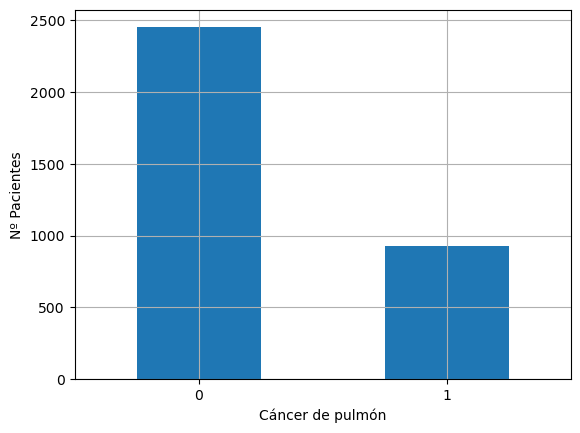

In [38]:
y_train.value_counts().sort_index().plot.bar(rot=0, grid=True)
plt.xlabel("Cáncer de pulmón")
plt.ylabel("Nº Pacientes")
plt.show()

## Distribución general de las variables explicativas

In [54]:
set_config(transform_output="pandas")
X_train_procesado = pipeline_final.named_steps['preprocesamiento'].transform(X_train)
X_EDA=X_train_procesado[variables_importantes]
X_EDA["cancer_pulmon"]=y_train

c:\Users\rtrin\OneDrive\Escritorio\FORMACION\MASTER\TFM\tfm-mulcia-2025\tfm-mulcia-2025\.pixi\envs\default\Lib\site-packages\sklearn\impute\_base.py:641: UserWarning: Skipping features without any observed values: ['J05']. At least one non-missing value is needed for imputation with strategy='constant'.
  warnings.warn(
C:\Users\rtrin\AppData\Local\Temp\ipykernel_2904\457844863.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X_EDA["cancer_pulmon"]=y_train


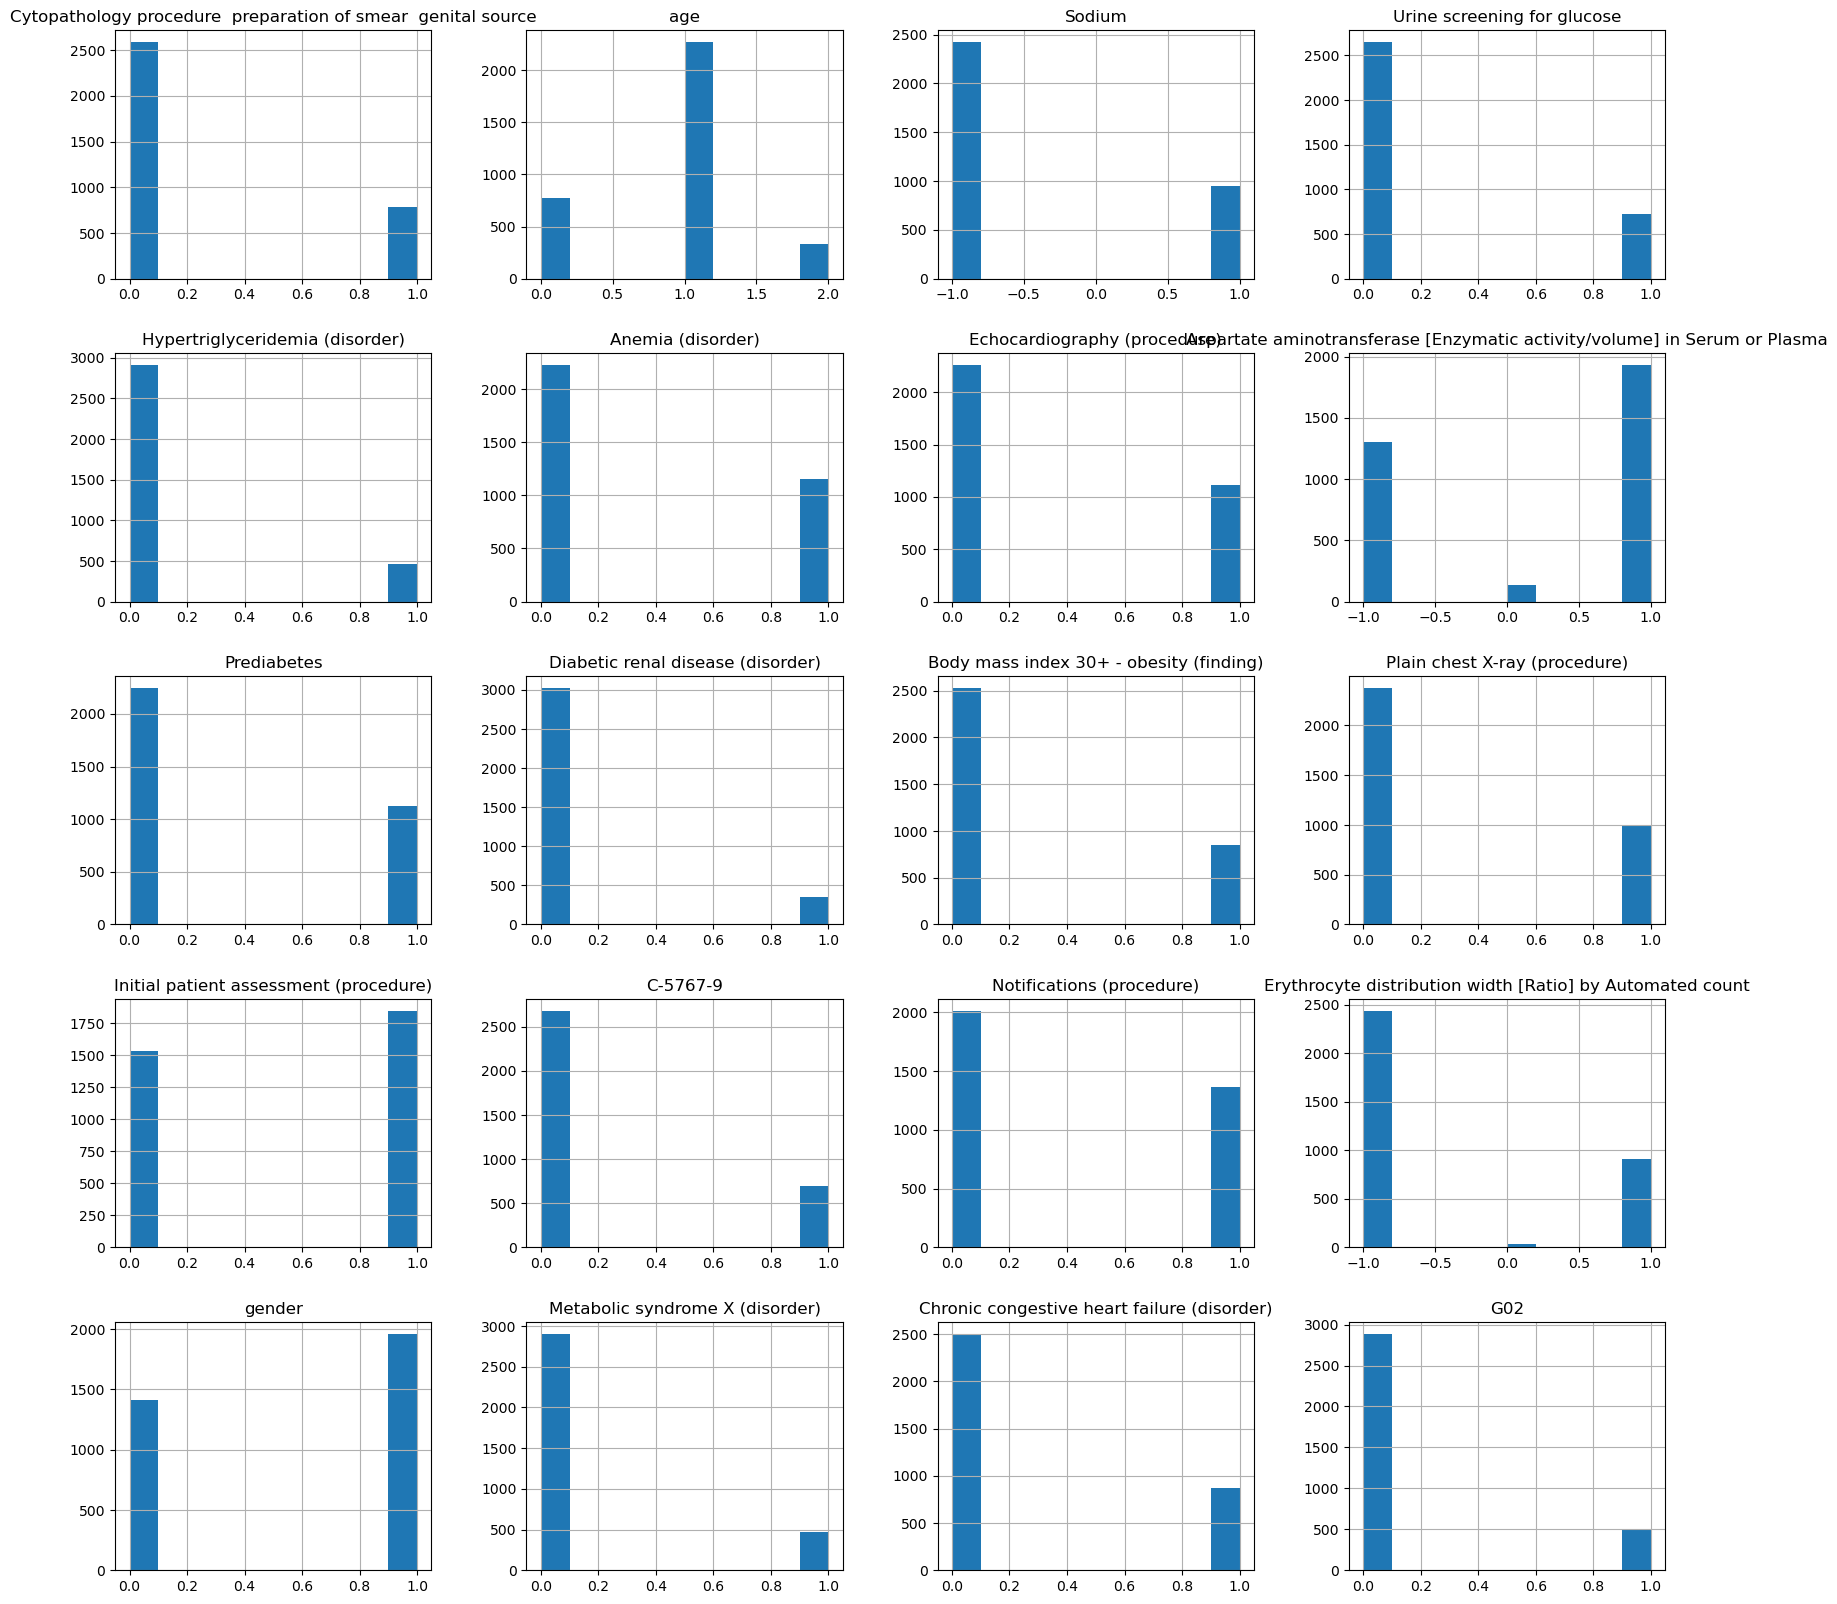

In [55]:
(X_EDA.drop(columns="cancer_pulmon")).hist(figsize=(20,20))
plt.show()


Principales hallazgos:
- Principalmente personas de mediana edad (Entre 50 y 70)
- Más hombres que mujeres en la muestra
- Sorprendete número de personas con anemia y prediabetes
- No hay variables numéricas entre las más importantes

## Influencia de Edad en la cohorte

<Axes: xlabel='age', ylabel='count'>

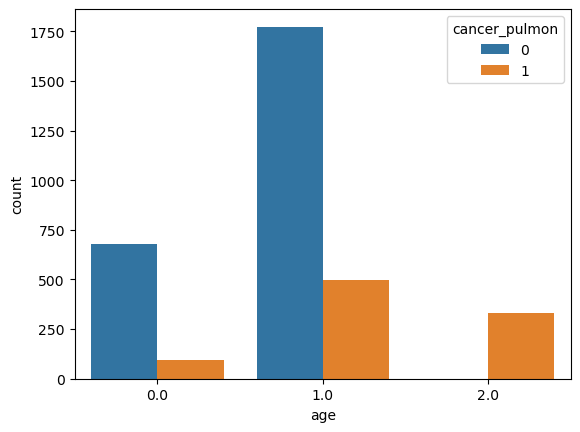

In [61]:
sns.countplot(data=X_EDA,x="age",hue="cancer_pulmon")

Todos las personas mayores de 70 años presentan cáncer. Esto explica la importancia de esta variable para el modelo. En este caso, lo mejor es eliminar los pacientes de este rango de edad.

## Influencia de Género en la cohorte

Text(0.5, 1.0, 'Afectación del cáncer en mujeres y hombres ')

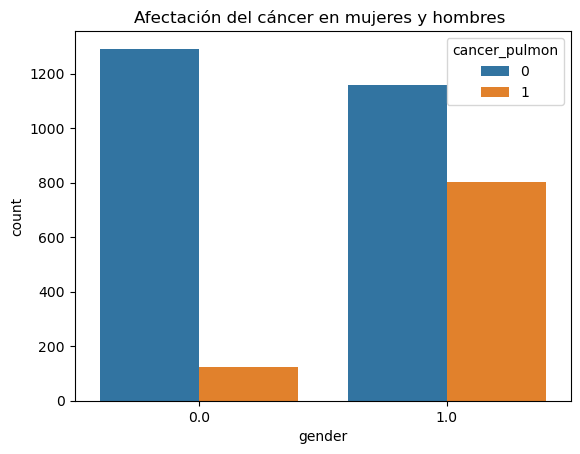

In [62]:
sns.countplot(data=X_EDA,x="gender",hue="cancer_pulmon")
plt.title("Afectación del cáncer en mujeres y hombres ")

Muchos más hombres afectados por cáncer que mujeres. 

## Influencia de Edad en la cohorte

<Axes: xlabel='Anemia (disorder)', ylabel='count'>

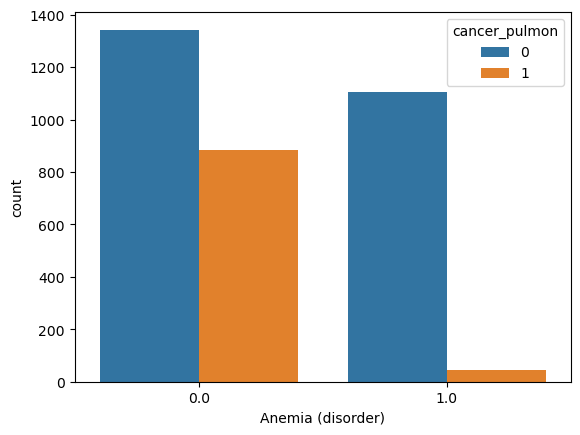

In [65]:
sns.countplot(data=X_EDA,x="Anemia (disorder)",hue="cancer_pulmon")

In [67]:
contingency = pd.crosstab(X_EDA["Anemia (disorder)"], X_EDA["cancer_pulmon"])

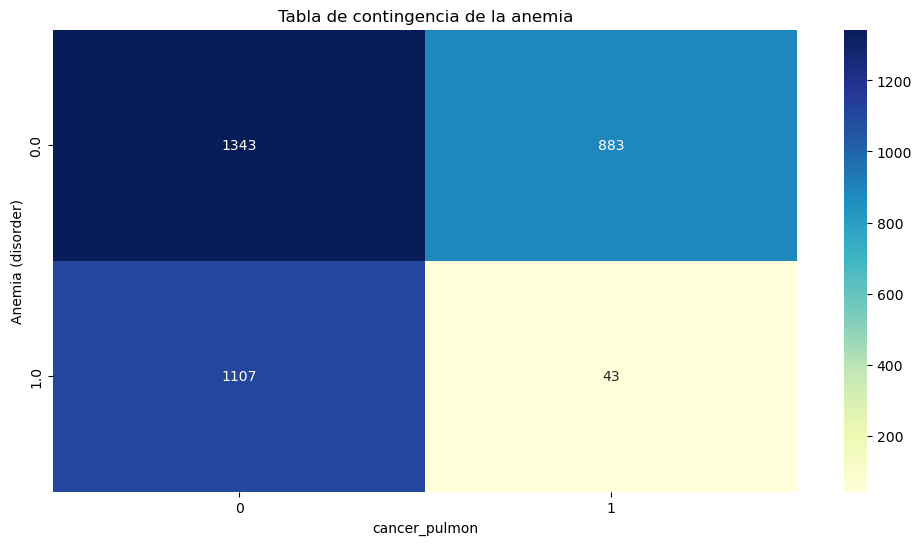

In [72]:
plt.figure(figsize=(12, 6))
sns.heatmap(contingency, annot=True, fmt="", cmap="YlGnBu")
plt.title("Tabla de contingencia de la anemia")
plt.show()
from scipy.stats import fisher_exact

odds_ratio,p_value=fisher_exact(contingency)

In [79]:
print(f"Se obtiene una relacion Odds ratio de {odds_ratio}")



Se obtiene una relacion Odds ratio de 0.05907940921613822


Se rechaza la hipótesis de que la anemia no tenga efecto en el cancer de pulmón. Siendo la anemia un factor protector del cáncer según la estadística.

# Eliminación sesgo por edad

In [92]:
set_config(transform_output="pandas")
X_train_procesado = pipeline_final.named_steps['preprocesamiento'].transform(X_train)
X_test_procesado = pipeline_final.named_steps['preprocesamiento'].transform(X_test)

mask_train_age=X_train_procesado["age"]!=2.0
mask_test_age=X_test_procesado["age"]!=2.0

X_train_procesado=X_train_procesado[mask_train_age]
y_train_procesado=y_train[mask_train_age]

X_test_procesado=X_test_procesado[mask_test_age]
y_test_procesado=y_test[mask_test_age]



c:\Users\rtrin\OneDrive\Escritorio\FORMACION\MASTER\TFM\tfm-mulcia-2025\tfm-mulcia-2025\.pixi\envs\default\Lib\site-packages\sklearn\impute\_base.py:641: UserWarning: Skipping features without any observed values: ['J05']. At least one non-missing value is needed for imputation with strategy='constant'.
  warnings.warn(
c:\Users\rtrin\OneDrive\Escritorio\FORMACION\MASTER\TFM\tfm-mulcia-2025\tfm-mulcia-2025\.pixi\envs\default\Lib\site-packages\sklearn\impute\_base.py:641: UserWarning: Skipping features without any observed values: ['J05']. At least one non-missing value is needed for imputation with strategy='constant'.
  warnings.warn(


# Explainable Boosting Machines

In [93]:
ebm = ExplainableBoostingClassifier(
    random_state=25,
    interactions=10 
)

In [95]:
ebm.fit(X_train_procesado,y_train_procesado)

c:\Users\rtrin\OneDrive\Escritorio\FORMACION\MASTER\TFM\tfm-mulcia-2025\tfm-mulcia-2025\.pixi\envs\default\Lib\site-packages\interpret\glassbox\_ebm\_ebm.py:871: UserWarning: Missing values detected. Our visualizations do not currently display missing values. To retain the glassbox nature of the model you need to either set the missing values to an extreme value like -1000 that will be visible on the graphs, or manually examine the missing value score in ebm.term_scores_[term_index][0]
  warn(


,feature_names,None
,feature_types,None
,max_bins,1024
,max_interaction_bins,64
,interactions,10
,exclude,None
,validation_size,0.15
,outer_bags,14
,inner_bags,0
,learning_rate,0.015
,greedy_ratio,10.0


In [98]:
y_pred =ebm.predict(X_test_procesado)

In [100]:
print(classification_report(y_test_procesado, y_pred))

              precision    recall  f1-score   support

           0       0.99      0.98      0.99       307
           1       0.94      0.98      0.96        83

    accuracy                           0.98       390
   macro avg       0.97      0.98      0.97       390
weighted avg       0.98      0.98      0.98       390



In [101]:
show(ebm.explain_global())

<!-- http://127.0.0.1:7001/1785158073232/ -->

Se observa que la edad deja de ser relevante sin embargo, los rendimientos no empeoran y siguen siendo exageradamente altos.